In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_df = pd.read_csv("../data/processed/train_df.csv")
test_df = pd.read_csv("../data/processed/test_df.csv")
rul_df = pd.read_csv("../data/processed/rul_df.csv")

In [3]:
print("Number of training engines:", train_df["unit_id"].nunique())
print("Number of testing engines:", test_df["unit_id"].nunique())

Number of training engines: 100
Number of testing engines: 100


In [4]:
cycle_per_engine = train_df.groupby("unit_id")["cycle"].max()

print(cycle_per_engine)
print("Average number of cycles per engine:", cycle_per_engine.mean())




unit_id
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64
Average number of cycles per engine: 206.31


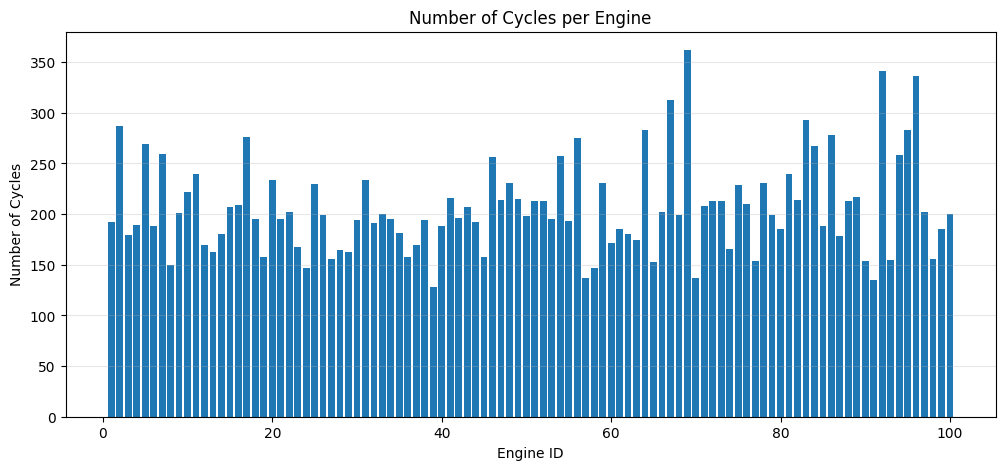

In [5]:
plt.figure(figsize=(12, 5))

plt.bar(
    cycle_per_engine.index,
    cycle_per_engine.values
)

plt.xlabel("Engine ID")
plt.ylabel("Number of Cycles")
plt.title("Number of Cycles per Engine")

plt.grid(axis="y", alpha=0.3)
plt.show()

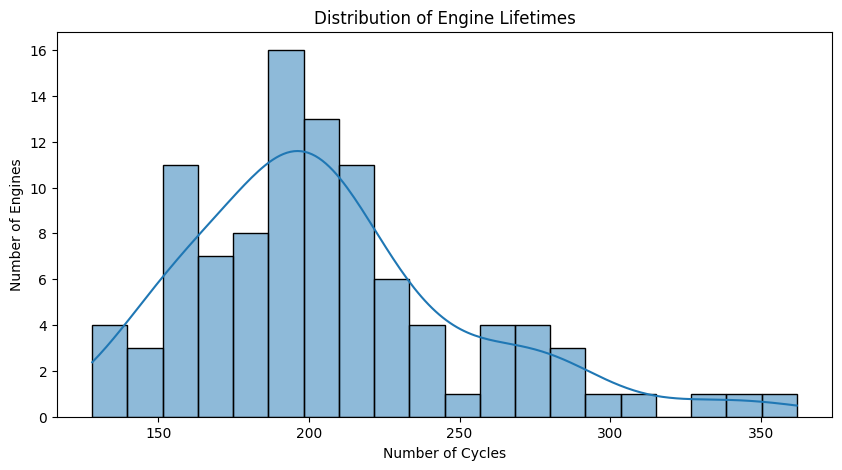

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    cycle_per_engine,
    bins=20,
    kde=True
)

plt.xlabel("Number of Cycles")
plt.ylabel("Number of Engines")
plt.title("Distribution of Engine Lifetimes")

plt.show()

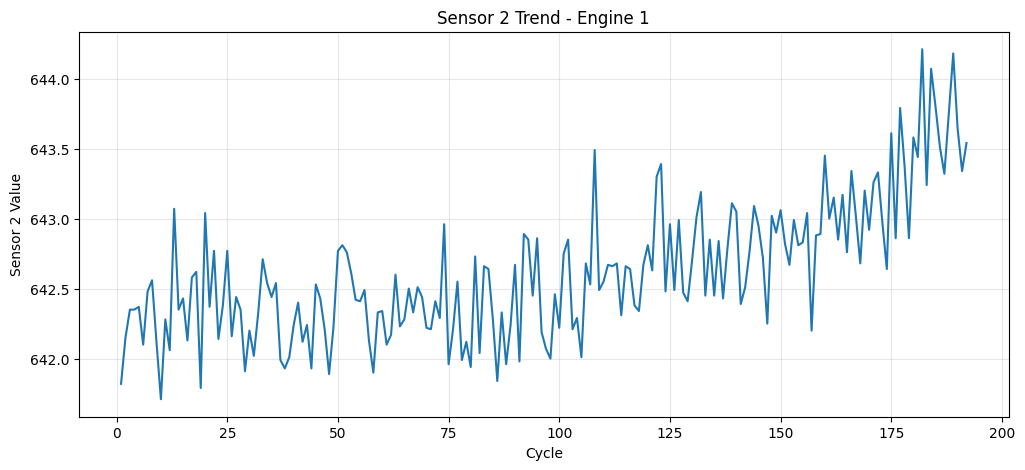

In [7]:
engine_id = 1

engine_data = train_df[
    train_df["unit_id"] == engine_id
]

plt.figure(figsize=(12, 5))

plt.plot(
    engine_data["cycle"],
    engine_data["sensor_2"]
)

plt.xlabel("Cycle")
plt.ylabel("Sensor 2 Value")
plt.title(f"Sensor 2 Trend - Engine {engine_id}")

plt.grid(alpha=0.3)
plt.show()

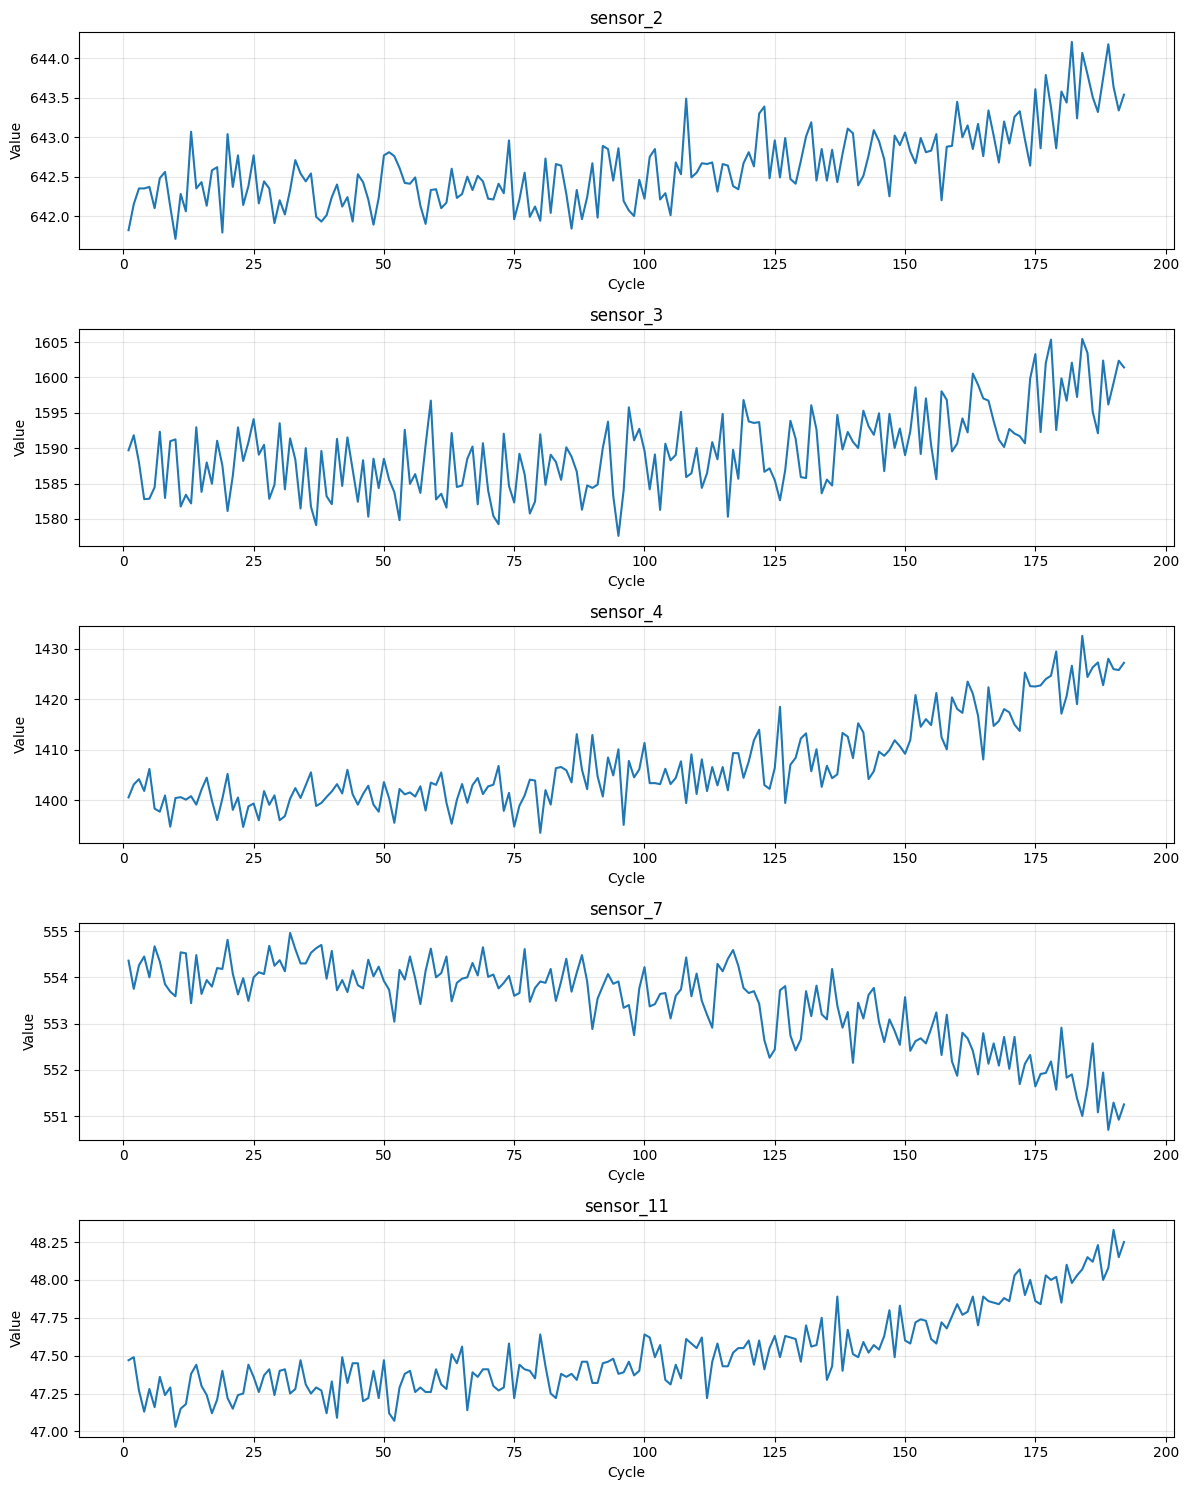

In [8]:
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11"
]

fig, axes = plt.subplots(
    len(selected_sensors),
    1,
    figsize=(12, 15)
)

for ax, sensor in zip(axes, selected_sensors):

    ax.plot(
        engine_data["cycle"],
        engine_data[sensor]
    )

    ax.set_title(sensor)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
sensor_cols = [
    col for col in train_df.columns
    if col.startswith("sensor_")
]

correlation_matrix = train_df[sensor_cols].corr()

display(correlation_matrix)

,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
sensor_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor_2,NaN,1.000000,0.602610,0.714949,NaN,0.132242,-0.702136,0.662325,0.273764,NaN,...,-0.724578,0.661792,0.179752,0.675975,NaN,0.629886,NaN,NaN,-0.661841,-0.668050
sensor_3,NaN,0.602610,1.000000,0.678413,NaN,0.116039,-0.664595,0.602481,0.322964,NaN,...,-0.680307,0.600963,0.237137,0.639921,NaN,0.600017,NaN,NaN,-0.625941,-0.633901
sensor_4,NaN,0.714949,0.678413,1.000000,NaN,0.150480,-0.793130,0.746852,0.297429,NaN,...,-0.815591,0.745158,0.190748,0.758459,NaN,0.703499,NaN,NaN,-0.748067,-0.745193
sensor_5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor_6,NaN,0.132242,0.116039,0.150480,NaN,1.000000,-0.155720,0.152161,0.019347,NaN,...,-0.155884,0.158276,-0.002112,0.149042,NaN,0.130810,NaN,NaN,-0.141419,-0.137419
sensor_7,NaN,-0.702136,-0.664595,-0.793130,NaN,-0.155720,1.000000,-0.767132,-0.217835,NaN,...,0.812713,-0.764611,-0.110053,-0.747051,NaN,-0.692893,NaN,NaN,0.736163,0.737447
sensor_8,NaN,0.662325,0.602481,0.746852,NaN,0.152161,-0.767132,1.000000,-0.032091,NaN,...,-0.786540,0.826084,-0.144787,0.700949,NaN,0.627785,NaN,NaN,-0.687030,-0.688840
sensor_9,NaN,0.273764,0.322964,0.297429,NaN,0.019347,-0.217835,-0.032091,1.000000,NaN,...,-0.210238,-0.034763,0.963157,0.293753,NaN,0.337110,NaN,NaN,-0.285280,-0.292795
sensor_10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


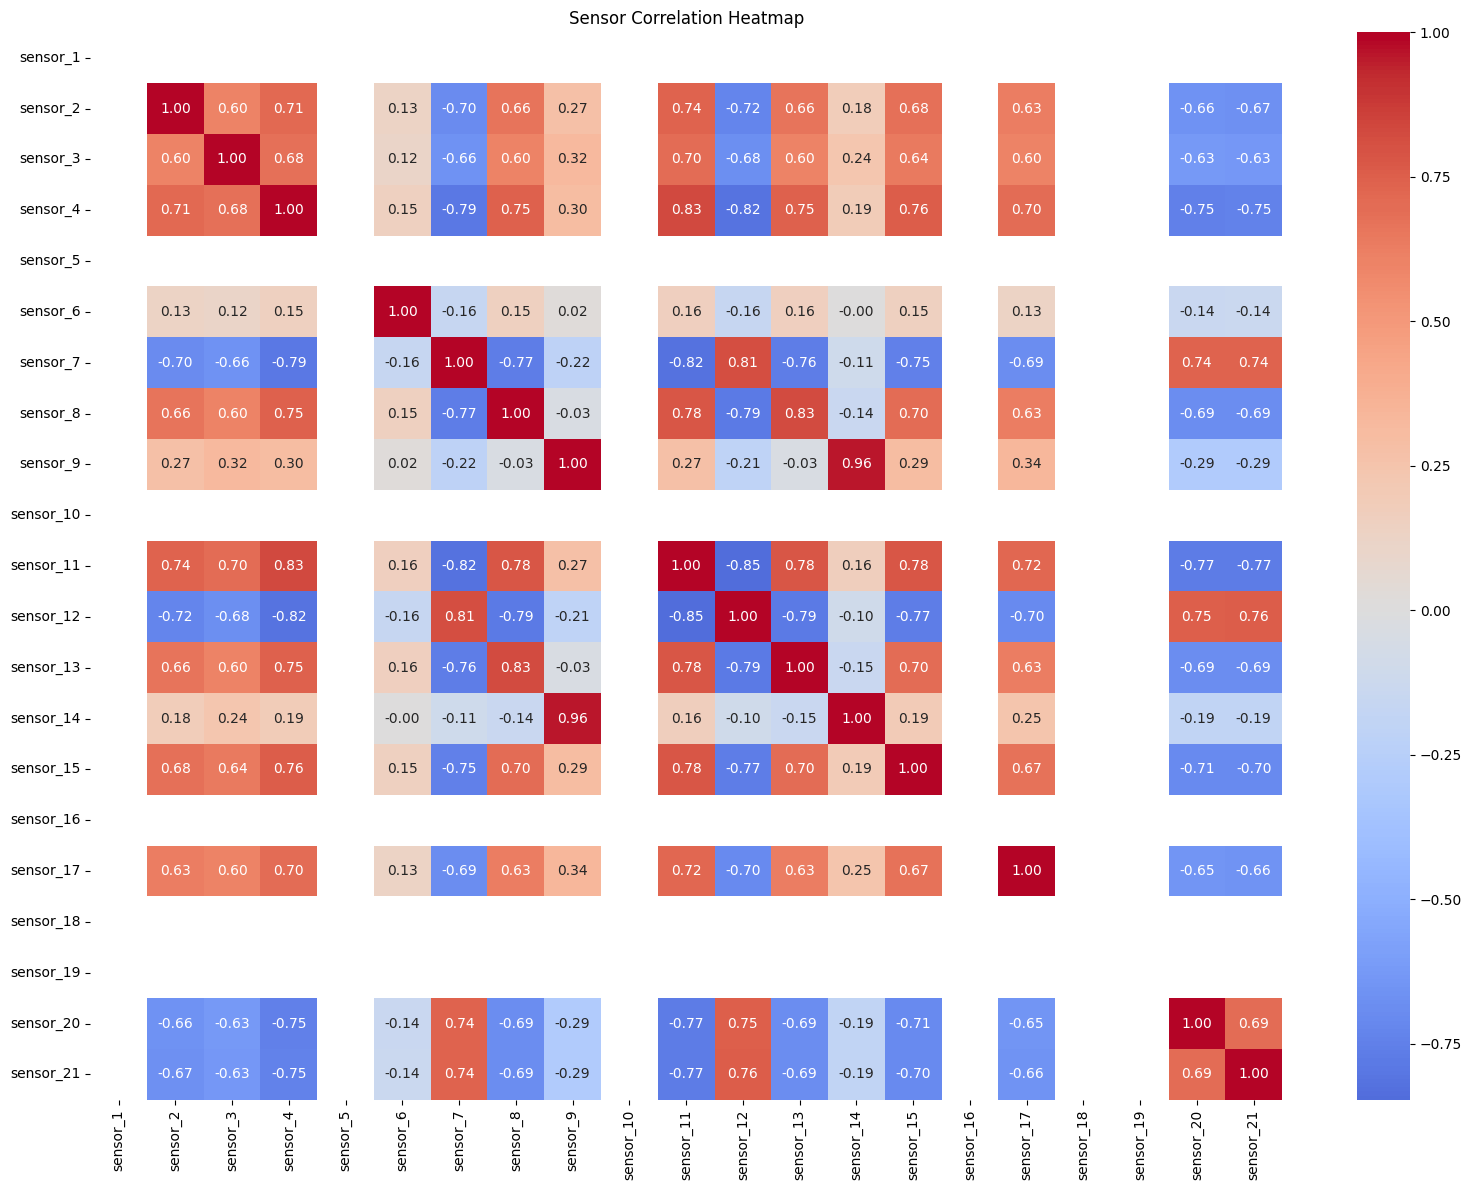

In [10]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Sensor Correlation Heatmap")
plt.tight_layout()
plt.show()

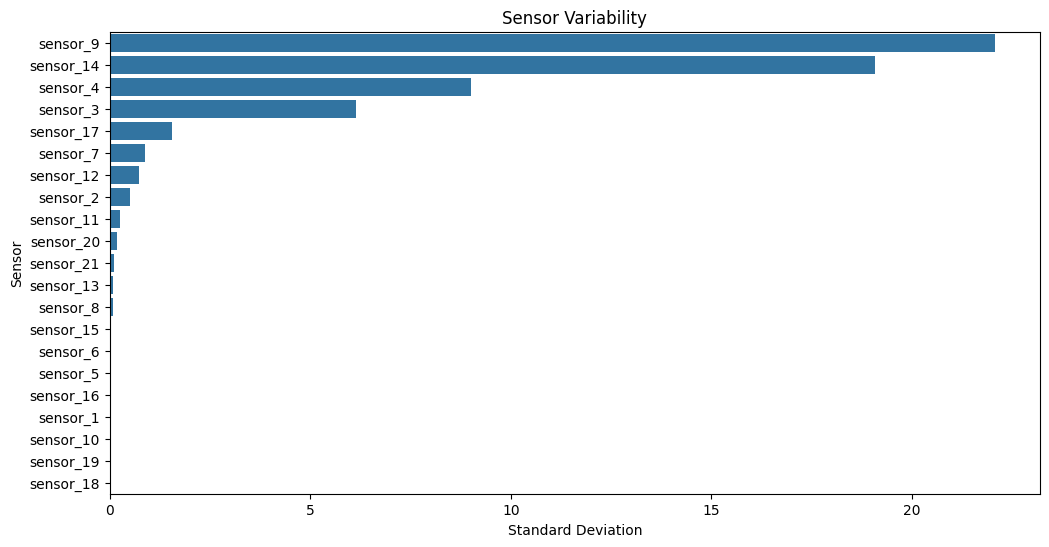

In [11]:
sensor_std = train_df[sensor_cols].std()

sensor_std = sensor_std.sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=sensor_std.values,
    y=sensor_std.index
)

plt.xlabel("Standard Deviation")
plt.ylabel("Sensor")
plt.title("Sensor Variability")

plt.show()

In [12]:
sensor_nunique = train_df[sensor_cols].nunique()

constant_sensors = sensor_nunique[
    sensor_nunique == 1
]

print("Constant sensors:")
print(constant_sensors)

Constant sensors:
sensor_1     1
sensor_5     1
sensor_10    1
sensor_16    1
sensor_18    1
sensor_19    1
dtype: int64


In [13]:
train_df[sensor_cols].nunique()

sensor_1        1
sensor_2      310
sensor_3     3012
sensor_4     4051
sensor_5        1
sensor_6        2
sensor_7      513
sensor_8       53
sensor_9     6403
sensor_10       1
sensor_11     159
sensor_12     427
sensor_13      56
sensor_14    6078
sensor_15    1918
sensor_16       1
sensor_17      13
sensor_18       1
sensor_19       1
sensor_20     120
sensor_21    4745
dtype: int64